# =========================================================
# RAIL DEFECT SEGMENTATION & SEVERITY PIPELINE (SINGLE FILE)
# Model: U-Net with EfficientNet-B0
# Task : Binary segmentation (class-wise folders)
# Class - Scabbing of Rails
# =========================================================

STEP 0️⃣ – GLOBAL SETTINGS (RUN FIRST)

In [3]:
!pip install segmentation-models-pytorch

In [4]:
import os
import cv2
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp


In [8]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TARGET_DEFECT = "Scabbing of Rails"
EPOCHS = 20
BATCH_SIZE = 4
LR = 1e-4


✅ Verify

In [9]:
print("Device:", DEVICE)
print("Target defect:", TARGET_DEFECT)


Device: cuda
Target defect: Scabbing of Rails


STEP 1️⃣ – DATASET CLASS (NO AUGMENTATION YET)

STEP 2️⃣ – DISPLAY FEW SAMPLES AFTER LOADING DATASET ✅ (POINT 1)

In [11]:
import os, cv2, torch, numpy as np
from torch.utils.data import Dataset

class RailDataset(Dataset):
    def __init__(self, defect_path, transform=None, skip_empty_masks=True):
        self.defect_path = defect_path
        self.image_dir = os.path.join(defect_path, "Images")
        self.mask_dir  = os.path.join(defect_path, "masks")
        self.transform = transform

        self.images = []

        for f in sorted(os.listdir(self.image_dir)):
            if not f.lower().endswith(('.png', '.jpg', '.jpeg')):
                continue

            img_path  = os.path.join(self.image_dir, f)
            name, _   = os.path.splitext(f)
            mask_path = os.path.join(self.mask_dir, name + ".png")

            if not os.path.exists(mask_path):
                continue

            if skip_empty_masks:
                mask = cv2.imread(mask_path, 0)
                if mask is None or np.sum(mask) == 0:
                    continue

            self.images.append(img_path)

        print(f"Loaded {len(self.images)} non-empty mask samples")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        img_name = os.path.basename(img_path)
        name, _ = os.path.splitext(img_name)

        mask_path = os.path.join(self.mask_dir, name + ".png")

        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(mask_path, 0)
        if mask is None:
            raise FileNotFoundError(f"Mask missing for {img_name}")

        mask = (mask > 0).astype("float32")

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"]
        else:
            image = torch.from_numpy(image).permute(2,0,1).float()

        mask = torch.tensor(mask).unsqueeze(0)

        return image, mask, img_name


In [13]:
def show_samples(dataset, n=3):
    plt.figure(figsize=(8, 3*n))

    for i in range(n):
        img, mask, _ = dataset[i]   # unpack image, mask, filename

        plt.subplot(n, 2, 2*i+1)
        plt.imshow(img.permute(1,2,0).numpy() / 255.0)  # ✅ FIX
        plt.title("Image")
        plt.axis("off")

        plt.subplot(n, 2, 2*i+2)
        plt.imshow(mask.squeeze(), cmap="gray")
        plt.title("Mask")
        plt.axis("off")

    plt.show()




Loaded 172 non-empty mask samples


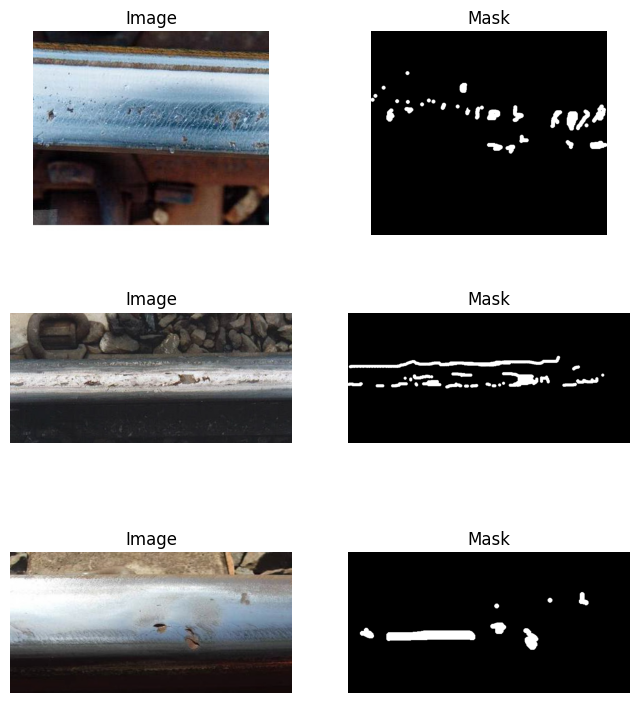

In [14]:
train_defect_path = "/kaggle/input/datasets/shreethabhat/severity-calculation-dataset-rail-track-defect/With Split/Training Set/Scabbing of Rails"

train_ds_plain = RailDataset(train_defect_path)
show_samples(train_ds_plain)


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


STEP 3️⃣ – ENVIRONMENT-WISE DATA AUGMENTATION + DISPLAY ✅ (POINT 2)

Morning

In [19]:
# -------------------------
# Sample environmental augmentations
# -------------------------
aug_rain = A.Compose([
    A.RandomRain(p=1.0)
])

"""aug_fog = A.Compose([
    A.RandomFog(
        fog_coef_lower=0.3,
        fog_coef_upper=0.6,
        alpha_coef=0.1,
        p=1.0
    )
])

aug_snow = A.Compose([
    A.RandomSnow(
        snow_point_lower=0.1,
        snow_point_upper=0.3,
        brightness_coeff=1.5,
        p=1.0
    )
])"""

# -------------------------
# Sample lighting augmentations
# -------------------------
aug_morning = A.Compose([
    A.RandomBrightnessContrast(
        brightness_limit=(0.1, 0.3),
        contrast_limit=(0, 0.1),
        p=1.0
    )
])

aug_evening = A.Compose([
    A.RandomBrightnessContrast(
        brightness_limit=(-0.3, -0.1),
        contrast_limit=(0, 0.1),
        p=1.0
    )
])

aug_night = A.Compose([
    A.RandomBrightnessContrast(
        brightness_limit=(-0.5, -0.3),
        contrast_limit=(0.1, 0.3),
        p=1.0
    )
])


In [21]:
def show_augmentations(dataset, aug_list, titles):
    img, mask, _ = dataset[0]

    # Convert tensor → numpy uint8 (Albumentations needs this)
    img = img.permute(1,2,0).numpy()
    img = (img * 255).astype(np.uint8) if img.max() <= 1.0 else img.astype(np.uint8)

    mask = mask.squeeze().numpy().astype(np.uint8)

    plt.figure(figsize=(18, 3))

    for i, aug in enumerate(aug_list):
        out = aug(image=img, mask=mask)

        aug_img = out["image"].astype(np.float32) / 255.0  # for display

        plt.subplot(1, len(aug_list), i+1)
        plt.imshow(aug_img)
        plt.title(titles[i])
        plt.axis("off")

    plt.show()



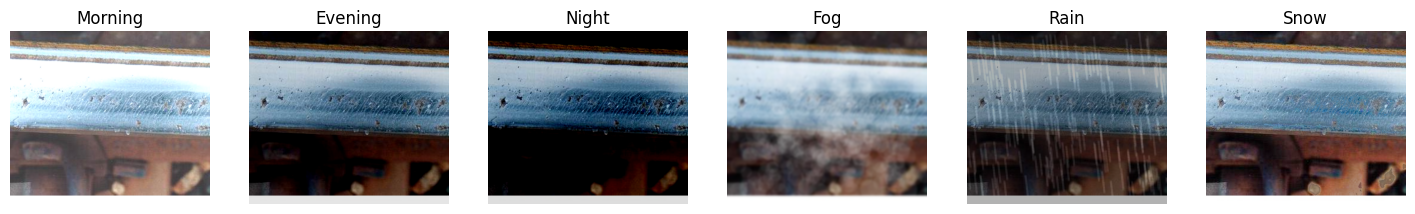

In [22]:
show_augmentations(
    train_ds_plain,
    [aug_morning, aug_evening, aug_night, aug_fog, aug_rain, aug_snow],
    ["Morning", "Evening", "Night", "Fog", "Rain", "Snow"]
)

STEP 4️⃣ – FINAL TRANSFORMS & LOADERS

In [25]:
from albumentations.pytorch import ToTensorV2

train_tfms = A.Compose([
    A.Resize(512, 512),

    A.HorizontalFlip(p=0.5),

    A.OneOf([
        aug_morning,
        aug_evening,
        aug_night,
        aug_fog,
        aug_rain
    ], p=0.7),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()   # ✅ THIS IS THE KEY FIX
])



In [30]:
val_tfms = A.Compose([
    A.Resize(512, 512),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])


In [31]:
train_ds = RailDataset("/kaggle/input/datasets/shreethabhat/severity-calculation-dataset-rail-track-defect/With Split/Training Set/Scabbing of Rails", train_tfms)
val_ds   = RailDataset("/kaggle/input/datasets/shreethabhat/severity-calculation-dataset-rail-track-defect/With Split/Validation Set/Scabbing of Rails", val_tfms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print("Train samples:", len(train_ds))
print("Val samples:", len(val_ds))


Loaded 172 non-empty mask samples
Loaded 38 non-empty mask samples
Train samples: 172
Val samples: 38


HOW TO VERIFY AUGMENTATION IS REALLY APPLIED (VISUAL PROOF)

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import torch

def show_augmented_samples(dataset, n=3):
    plt.figure(figsize=(8, 4*n))

    for i in range(n):
        img, mask, name = dataset[i]

        # ---------- IMAGE ----------
        if isinstance(img, torch.Tensor):
            img = img.detach().cpu()
            img = img.permute(1, 2, 0).numpy()
        elif isinstance(img, np.ndarray):
            if img.ndim == 3:
                pass
            else:
                raise ValueError("Unexpected image shape")

        # Normalize only for display
        img = img - img.min()
        if img.max() > 0:
            img = img / img.max()

        # ---------- MASK ----------
        if isinstance(mask, torch.Tensor):
            mask = mask.detach().cpu().squeeze().numpy()
        elif isinstance(mask, np.ndarray):
            mask = mask.squeeze()

        plt.subplot(n, 2, 2*i+1)
        plt.imshow(img)
        plt.title(f"Augmented Image\n{name}")
        plt.axis("off")

        plt.subplot(n, 2, 2*i+2)
        plt.imshow(mask, cmap="gray")
        plt.title("Mask")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


/tmp/ipykernel_58/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


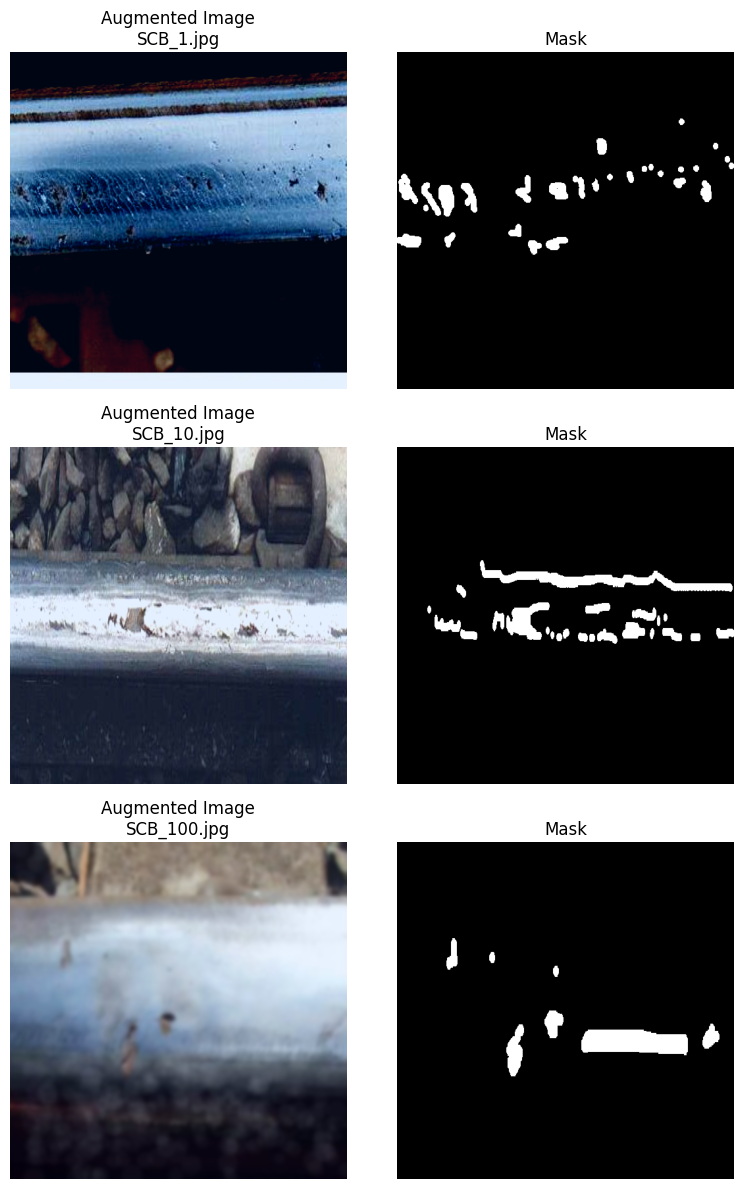

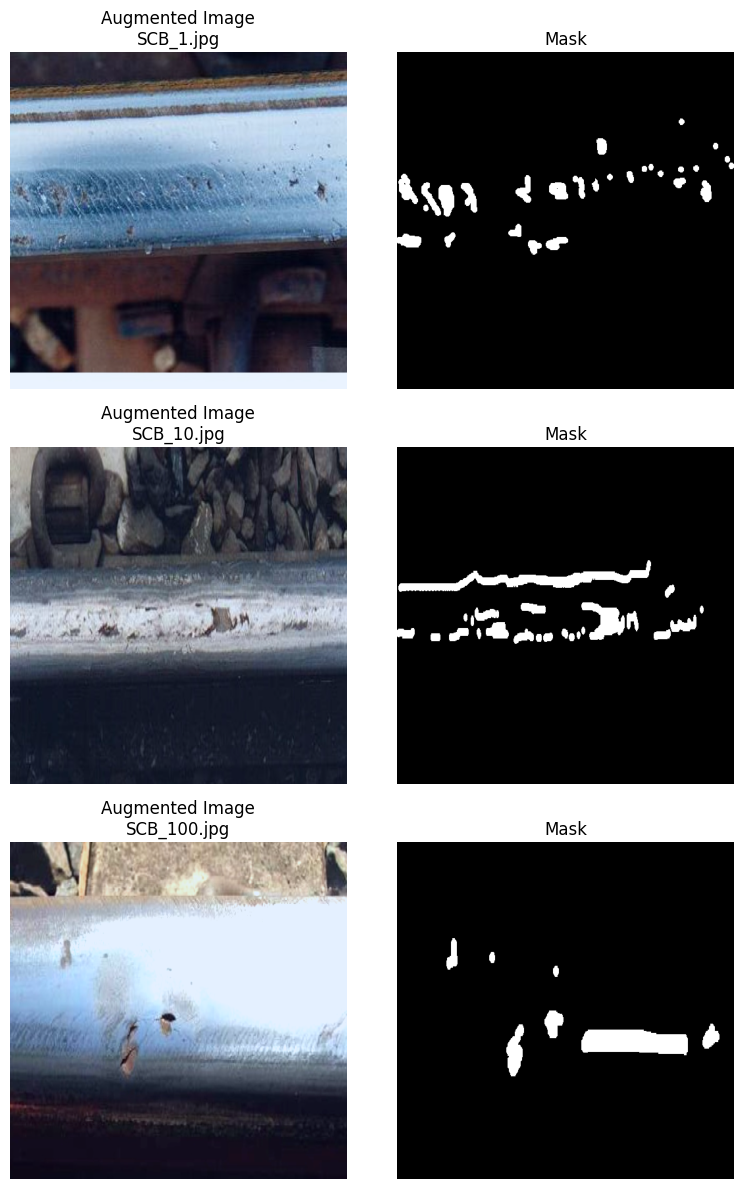

In [35]:
show_augmented_samples(train_ds)
show_augmented_samples(train_ds)


STEP 5️⃣ – MODEL, LOSS, METRICS ✅ (POINT 3)

In [36]:
model = smp.Unet(
    encoder_name="efficientnet-b0",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1
).to(DEVICE)



config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

In [38]:
from scipy.ndimage import distance_transform_edt

def boundary_loss(pred, gt):
    """
    Normalized boundary loss (stable).
    """
    gt_np = gt.detach().cpu().numpy()

    # Distance transform
    dist = distance_transform_edt(1 - gt_np)

    # Normalize distance map to [0,1]
    dist = dist / (dist.max() + 1e-8)

    dist = torch.tensor(dist, device=pred.device).float()

    pred = torch.sigmoid(pred)

    return (pred * dist).mean()




In [40]:
# =========================
# OPTION 2: FOCAL TVERSKY LOSS
# =========================

bce = nn.BCEWithLogitsLoss()

tversky = smp.losses.TverskyLoss(
    mode="binary",
    alpha=0.7,
    beta=0.3
)

def loss_fn(pred, gt):
    return (
        0.50 * bce(pred, gt) +
        0.40 * tversky(pred, gt) +
        0.10 * boundary_loss(pred, gt)
    )




In [41]:
def dice_score(pred, gt, eps=1e-7):
    pred = (torch.sigmoid(pred) > 0.5).float()
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum()
    return (2*inter + eps) / (union + eps)


Hausdorff distance

In [42]:
from scipy.spatial.distance import directed_hausdorff
import numpy as np


In [43]:
def hausdorff_distance(pred_mask, gt_mask):
    """
    Computes symmetric Hausdorff Distance (in pixels)
    pred_mask, gt_mask: binary numpy arrays (H,W)
    """
    pred_pts = np.argwhere(pred_mask > 0)
    gt_pts   = np.argwhere(gt_mask > 0)

    # If either mask is empty, HD is undefined → return large value
    if len(pred_pts) == 0 or len(gt_pts) == 0:
        return np.nan

    hd1 = directed_hausdorff(pred_pts, gt_pts)[0]
    hd2 = directed_hausdorff(gt_pts, pred_pts)[0]

    return max(hd1, hd2)


STEP 6️⃣ – TRAINING + ALL METRICS + RUNTIME ✅ (POINT 4)

6.1 METRIC FUNCTIONS (ADD ONCE)

In [44]:
def iou_score(pred, gt, eps=1e-7):
    pred = (torch.sigmoid(pred) > 0.5).float()
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum() - inter
    return (inter + eps) / (union + eps)

def pixel_accuracy(pred, gt):
    pred = (torch.sigmoid(pred) > 0.5).float()
    correct = (pred == gt).float().sum()
    total = torch.numel(pred)
    return correct / total

def precision_score(pred, gt, eps=1e-7):
    pred = (torch.sigmoid(pred) > 0.5).float()
    tp = (pred * gt).sum()
    fp = (pred * (1 - gt)).sum()
    return (tp + eps) / (tp + fp + eps)

def recall_score(pred, gt, eps=1e-7):
    pred = (torch.sigmoid(pred) > 0.5).float()
    tp = (pred * gt).sum()
    fn = ((1 - pred) * gt).sum()
    return (tp + eps) / (tp + fn + eps)


6.2 HISTORY DICTIONARY (FOR CURVES LATER)

In [45]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    #verbose=True
)


start_time = time.time()



In [46]:
history = {
    # Loss
    "train_loss": [],
    "val_loss": [],

    # Dice & IoU
    "train_dice": [],
    "val_dice": [],
    "train_iou": [],
    "val_iou": [],

    # Accuracy / Precision / Recall
    "train_acc": [],
    "val_acc": [],
    "train_prec": [],
    "val_prec": [],
    "train_rec": [],
    "val_rec": [],

    # Hausdorff
    "train_hd": [],
    "val_hd": []
}


In [47]:
best_val_dice = 0.0
epoch_times = []
total_training_start = time.time()

for epoch in range(EPOCHS):
    epoch_start = time.time()

    # ================= TRAIN =================
    model.train()
    tl = td = ti = tacc = tprec = trec = 0.0

    train_hd = []

    for imgs, masks, _ in train_loader:   # ✅ FIXED
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        preds = model(imgs)
        loss = loss_fn(preds, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        tl += loss.item()
        td += dice_score(preds, masks).item()
        ti += iou_score(preds, masks).item()
        tacc  += pixel_accuracy(preds, masks).item()
        tprec += precision_score(preds, masks).item()
        trec  += recall_score(preds, masks).item()


        # Hausdorff (TRAIN)
        preds_bin = (torch.sigmoid(preds) > 0.5).float()
        for i in range(preds_bin.size(0)):
            pred_np = preds_bin[i, 0].cpu().numpy()
            gt_np   = masks[i, 0].cpu().numpy()
            hd = hausdorff_distance(pred_np, gt_np)
            if not np.isnan(hd):
                train_hd.append(hd)

    tl /= len(train_loader)
    td /= len(train_loader)
    ti /= len(train_loader)
    tacc  /= len(train_loader)
    tprec /= len(train_loader)
    trec  /= len(train_loader)

    mean_train_hd = np.mean(train_hd) if len(train_hd) > 0 else np.nan
    history["train_hd"].append(mean_train_hd)

    # ================= VALIDATION =================
    model.eval()
    vl = vd = vi = vacc = vprec = vrec = 0.0
    val_hd = []

    with torch.no_grad():
        for imgs, masks, _ in val_loader:   # ✅ FIXED
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            preds = model(imgs)

            vl += loss_fn(preds, masks).item()
            vd += dice_score(preds, masks).item()
            vi += iou_score(preds, masks).item()
            vacc += pixel_accuracy(preds, masks).item()
            vprec += precision_score(preds, masks).item()
            vrec += recall_score(preds, masks).item()

            # Hausdorff (VAL)
            preds_bin = (torch.sigmoid(preds) > 0.5).float()
            for i in range(preds_bin.size(0)):
                pred_np = preds_bin[i, 0].cpu().numpy()
                gt_np   = masks[i, 0].cpu().numpy()
                hd = hausdorff_distance(pred_np, gt_np)
                if not np.isnan(hd):
                    val_hd.append(hd)

    vl /= len(val_loader)
    vd /= len(val_loader)
    vi /= len(val_loader)
    vacc /= len(val_loader)
    vprec /= len(val_loader)
    vrec /= len(val_loader)
    mean_val_hd = np.mean(val_hd) if len(val_hd) > 0 else np.nan
    history["val_hd"].append(mean_val_hd)

    scheduler.step(vd)

    # ================= SAVE HISTORY =================
    history["train_loss"].append(tl)
    history["val_loss"].append(vl)
    history["train_dice"].append(td)
    history["val_dice"].append(vd)
    history["train_iou"].append(ti)
    history["val_iou"].append(vi)
    history["train_acc"].append(tacc)
    history["val_acc"].append(vacc)
    history["train_prec"].append(tprec)
    history["val_prec"].append(vprec)
    history["train_rec"].append(trec)
    history["val_rec"].append(vrec)





    # ================= SAVE BEST MODEL =================
    if vd > best_val_dice:
        best_val_dice = vd
        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_dice": best_val_dice,
            "architecture": "Unet++",
            "encoder": "efficientnet-b0",
            "defect": "Rail Wear",
            "image_size": 512
        }
        torch.save(checkpoint, "best_unetpp_effb0_SCB.pth")

    # ================= RUNTIME =================
    epoch_time = time.time() - epoch_start
    epoch_times.append(epoch_time)

    # ================= PRINT METRICS (COMPLETE) =================
    print(
    f"Epoch [{epoch+1}/{EPOCHS}] | Time {epoch_time:.1f}s\n"
    f"  Train → Loss={tl:.4f}, Dice={td:.4f}, IoU={ti:.4f}, "
    f"Acc={tacc:.4f}, Prec={tprec:.4f}, Rec={trec:.4f}, HD={mean_train_hd:.2f}px\n"
    f"  Val   → Loss={vl:.4f}, Dice={vd:.4f}, IoU={vi:.4f}, "
    f"Acc={vacc:.4f}, Prec={vprec:.4f}, Rec={vrec:.4f}, HD={mean_val_hd:.2f}px\n"
    )


# ================= TOTAL TIME =================
total_training_time = time.time() - total_training_start
print("Total training time:", total_training_time)
print("Avg epoch time:", sum(epoch_times) / len(epoch_times))




/tmp/ipykernel_58/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


Epoch [1/20] | Time 396.2s
  Train → Loss=0.9347, Dice=0.1663, IoU=0.0923, Acc=0.2349, Prec=0.0931, Rec=0.9345, HD=305.24px
  Val   → Loss=0.8630, Dice=0.2311, IoU=0.1317, Acc=0.3177, Prec=0.1321, Rec=0.9747, HD=292.19px

Epoch [2/20] | Time 155.0s
  Train → Loss=0.7776, Dice=0.2156, IoU=0.1229, Acc=0.4826, Prec=0.1264, Rec=0.8532, HD=305.07px
  Val   → Loss=0.6883, Dice=0.3389, IoU=0.2080, Acc=0.6817, Prec=0.2205, Rec=0.7728, HD=291.94px

Epoch [3/20] | Time 62.8s
  Train → Loss=0.6571, Dice=0.3339, IoU=0.2044, Acc=0.7868, Prec=0.2369, Rec=0.6728, HD=304.67px
  Val   → Loss=0.6029, Dice=0.4365, IoU=0.2870, Acc=0.8422, Prec=0.3626, Rec=0.5930, HD=290.74px

Epoch [4/20] | Time 49.3s
  Train → Loss=0.6094, Dice=0.3958, IoU=0.2508, Acc=0.8705, Prec=0.3306, Rec=0.5528, HD=301.13px
  Val   → Loss=0.5679, Dice=0.4831, IoU=0.3268, Acc=0.8886, Prec=0.4887, Rec=0.5090, HD=269.09px

Epoch [5/20] | Time 48.6s
  Train → Loss=0.5747, Dice=0.4391, IoU=0.2884, Acc=0.9005, Prec=0.4185, Rec=0.5159, HD=

ADD THIS FUNCTION (RUN AFTER TRAINING)

In [51]:
import numpy as np
import torch

def find_best_iou_threshold(model, val_loader):
    model.eval()
    thresholds = np.arange(0.4, 0.8, 0.05)

    best_iou = 0.0
    best_t = 0.5

    with torch.no_grad():
        for t in thresholds:
            iou_sum = 0.0

            for imgs, masks, _ in val_loader:   # ✅ FIX HERE
                imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
                probs = torch.sigmoid(model(imgs))
                preds = (probs > t).float()
                iou_sum += iou_score(preds, masks).item()

            mean_iou = iou_sum / len(val_loader)

            print(f"Threshold {t:.2f} → IoU {mean_iou:.4f}")

            if mean_iou > best_iou:
                best_iou = mean_iou
                best_t = t

    print(f"\n✔ Best threshold = {best_t:.2f}, IoU = {best_iou:.4f}")
    return best_t, best_iou


In [52]:
best_t, best_iou = find_best_iou_threshold(model, val_loader)



/tmp/ipykernel_58/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


Threshold 0.40 → IoU 0.5175
Threshold 0.45 → IoU 0.5121
Threshold 0.50 → IoU 0.5054
Threshold 0.55 → IoU 0.4976
Threshold 0.60 → IoU 0.4883
Threshold 0.65 → IoU 0.4761
Threshold 0.70 → IoU 0.4601
Threshold 0.75 → IoU 0.4398

✔ Best threshold = 0.40, IoU = 0.5175


STEP 7️⃣ – ACCURACY & LOSS CURVES ✅ (POINT 5)

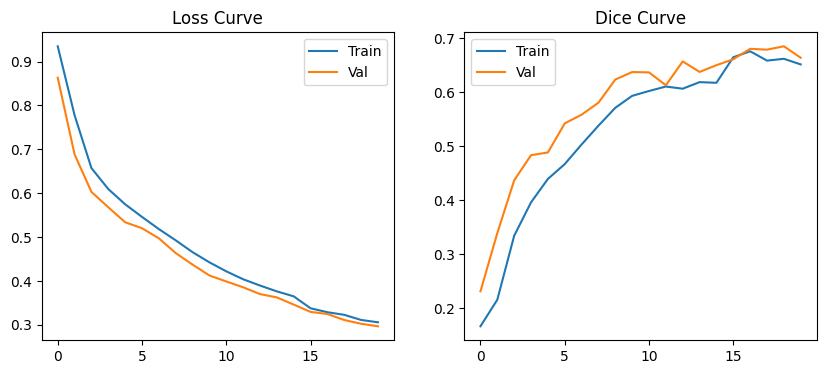

In [53]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history["train_loss"], label="Train")
plt.plot(history["val_loss"], label="Val")
plt.title("Loss Curve")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history["train_dice"], label="Train")
plt.plot(history["val_dice"], label="Val")
plt.title("Dice Curve")
plt.legend()
plt.show()




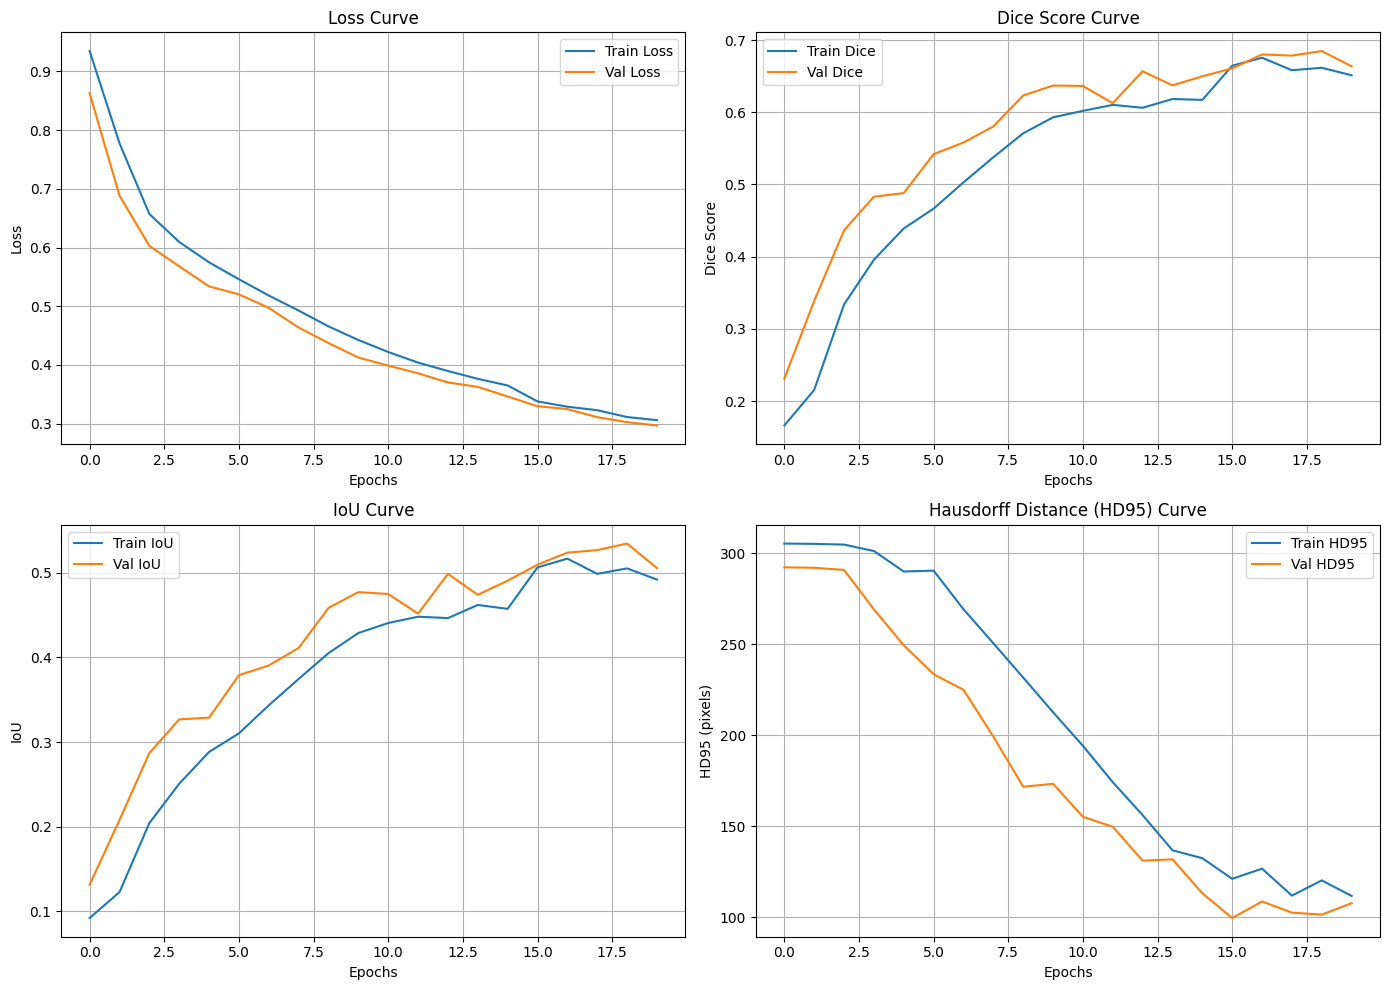

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

# ---------------- Loss Curve ----------------
plt.subplot(2, 2, 1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Val Loss")
plt.title("Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# ---------------- Dice Curve ----------------
plt.subplot(2, 2, 2)
plt.plot(history["train_dice"], label="Train Dice")
plt.plot(history["val_dice"], label="Val Dice")
plt.title("Dice Score Curve")
plt.xlabel("Epochs")
plt.ylabel("Dice Score")
plt.legend()
plt.grid(True)

# ---------------- IoU Curve ----------------
plt.subplot(2, 2, 3)
plt.plot(history["train_iou"], label="Train IoU")
plt.plot(history["val_iou"], label="Val IoU")
plt.title("IoU Curve")
plt.xlabel("Epochs")
plt.ylabel("IoU")
plt.legend()
plt.grid(True)

# ---------------- Hausdorff Distance Curve ----------------
plt.subplot(2, 2, 4)
plt.plot(history["train_hd"], label="Train HD95")
plt.plot(history["val_hd"], label="Val HD95")
plt.title("Hausdorff Distance (HD95) Curve")
plt.xlabel("Epochs")
plt.ylabel("HD95 (pixels)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


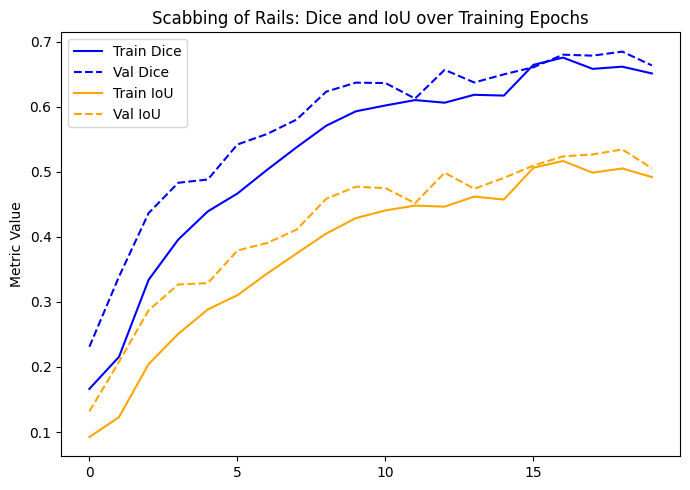

In [55]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(len(history["train_dice"]))

plt.figure(figsize=(7,5))

# Dice
plt.plot(epochs, history["train_dice"], label="Train Dice", color="blue", linestyle="-")
plt.plot(epochs, history["val_dice"], label="Val Dice", color="blue", linestyle="--")

# IoU
plt.plot(epochs, history["train_iou"], label="Train IoU", color="orange", linestyle="-")
plt.plot(epochs, history["val_iou"], label="Val IoU", color="orange", linestyle="--")

plt.title("Scabbing of Rails: Dice and IoU over Training Epochs")
plt.xticks(np.arange(0, len(epochs), 5))
plt.ylabel("Metric Value")
plt.legend()
plt.tight_layout()
plt.show()



Apply CRF post-processing once

In [56]:
import time
import numpy as np
import torch
import torch.nn as nn
from scipy.spatial.distance import directed_hausdorff



In [57]:
def hausdorff_distance_95(pred_mask, gt_mask):
    pred_pts = np.argwhere(pred_mask > 0)
    gt_pts   = np.argwhere(gt_mask > 0)

    if len(pred_pts) == 0 or len(gt_pts) == 0:
        return np.nan

    d1 = directed_hausdorff(pred_pts, gt_pts)[0]
    d2 = directed_hausdorff(gt_pts, pred_pts)[0]

    return np.percentile([d1, d2], 95)


In [58]:
best_val_dice = 0.0
epoch_times = []
total_start = time.time()


#BEST_MODEL_PATH = "/content/unetpp_efficientnetb0_SCB_best.pth"

for epoch in range(EPOCHS):
    start = time.time()

    # ================= TRAIN =================
    model.train()
    tl = td = ti = tacc = tprec = trec = 0.0


    for imgs, masks , _ in train_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        preds = model(imgs)
        loss = loss_fn(preds, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        tl += loss.item()
        td += dice_score(preds, masks).item()
        ti += iou_score(preds, masks).item()
        tacc  += pixel_accuracy(preds, masks).item()
        tprec += precision_score(preds, masks).item()
        trec  += recall_score(preds, masks).item()


    tl /= len(train_loader)
    td /= len(train_loader)
    ti /= len(train_loader)
    tacc  /= len(train_loader)
    tprec /= len(train_loader)
    trec  /= len(train_loader)


    # ================= VALIDATION =================
    model.eval()
    vl = vd = vi = vacc = vprec = vrec = 0.0
    val_hd95 = []

    with torch.no_grad():
        for imgs, masks, _ in val_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            preds = model(imgs)

            vl += loss_fn(preds, masks).item()
            vd += dice_score(preds, masks).item()
            vi += iou_score(preds, masks).item()
            vacc += pixel_accuracy(preds, masks).item()
            vprec += precision_score(preds, masks).item()
            vrec += recall_score(preds, masks).item()

            probs = torch.sigmoid(preds)

            for i in range(imgs.size(0)):
                 pred_bin = (probs[i,0] > 0.5).cpu().numpy()
                 gt_np    = masks[i,0].cpu().numpy()

                 hd95 = hausdorff_distance_95(pred_bin, gt_np)
                 if not np.isnan(hd95):
                     val_hd95.append(hd95)

    vl /= len(val_loader)
    vd /= len(val_loader)
    vi /= len(val_loader)
    vacc /= len(val_loader)
    vprec /= len(val_loader)
    vrec /= len(val_loader)
    mean_hd95 = np.mean(val_hd95)

    # ================= SAVE BEST MODEL =================
    if vd > best_val_dice:
        best_val_dice = vd
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "best_val_dice": best_val_dice
        }, "best_unetpp_effb0_SCB.pth")

    epoch_time = time.time() - start
    epoch_times.append(epoch_time)

    print(
    f"Epoch [{epoch+1}/{EPOCHS}] | Time {epoch_time:.1f}s\n"
    f"  Train → Loss={tl:.4f}, Dice={td:.4f}, IoU={ti:.4f}, "
    f"Acc={tacc:.4f}, Prec={tprec:.4f}, Rec={trec:.4f}, HD={mean_train_hd:.2f}px\n"
    f"  Val   → Loss={vl:.4f}, Dice={vd:.4f}, IoU={vi:.4f}, "
    f"Acc={vacc:.4f}, Prec={vprec:.4f}, Rec={vrec:.4f}, HD={mean_val_hd:.2f}px\n"
    )

print("\nTotal training time:", time.time() - total_start)
print("Avg epoch time:", sum(epoch_times)/len(epoch_times))


/tmp/ipykernel_58/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


Epoch [1/20] | Time 39.2s
  Train → Loss=0.2867, Dice=0.6808, IoU=0.5282, Acc=0.9490, Prec=0.6783, Rec=0.7122, HD=111.67px
  Val   → Loss=0.3042, Dice=0.6637, IoU=0.5036, Acc=0.9323, Prec=0.7101, Rec=0.6409, HD=107.70px

Epoch [2/20] | Time 42.4s
  Train → Loss=0.2837, Dice=0.6722, IoU=0.5192, Acc=0.9460, Prec=0.6639, Rec=0.7331, HD=111.67px
  Val   → Loss=0.3035, Dice=0.6501, IoU=0.4874, Acc=0.9295, Prec=0.7101, Rec=0.6227, HD=107.70px

Epoch [3/20] | Time 40.2s
  Train → Loss=0.2678, Dice=0.6865, IoU=0.5304, Acc=0.9493, Prec=0.6908, Rec=0.7126, HD=111.67px
  Val   → Loss=0.2749, Dice=0.6828, IoU=0.5274, Acc=0.9369, Prec=0.7321, Rec=0.6598, HD=107.70px

Epoch [4/20] | Time 42.6s
  Train → Loss=0.2641, Dice=0.6871, IoU=0.5295, Acc=0.9497, Prec=0.6954, Rec=0.7144, HD=111.67px
  Val   → Loss=0.2747, Dice=0.6835, IoU=0.5272, Acc=0.9343, Prec=0.7056, Rec=0.6786, HD=107.70px

Epoch [5/20] | Time 40.6s
  Train → Loss=0.2526, Dice=0.6999, IoU=0.5477, Acc=0.9512, Prec=0.7028, Rec=0.7252, HD=11

Save Model

In [59]:
import torch

# --------------------------------------------------
# SAVE TRAINED UNet++ EfficientNet-B0 MODEL
# --------------------------------------------------

SAVE_PATH = "best_unetpp_effb0_SCB.pth"

# Save only the model weights (best practice)
torch.save(model.state_dict(), SAVE_PATH)

print("✅ Trained model saved successfully")
print("📁 Model path:", SAVE_PATH)


✅ Trained model saved successfully
📁 Model path: best_unetpp_effb0_SCB.pth


Draw Graph

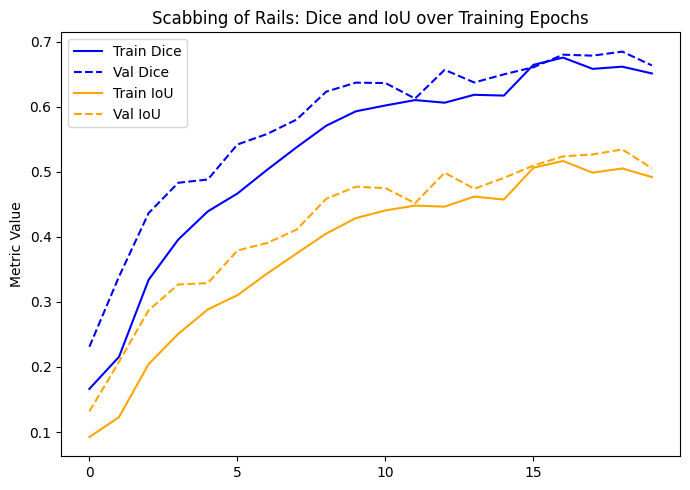

In [60]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(len(history["train_dice"]))

plt.figure(figsize=(7,5))

# Dice
plt.plot(epochs, history["train_dice"], label="Train Dice", color="blue", linestyle="-")
plt.plot(epochs, history["val_dice"], label="Val Dice", color="blue", linestyle="--")

# IoU
plt.plot(epochs, history["train_iou"], label="Train IoU", color="orange", linestyle="-")
plt.plot(epochs, history["val_iou"], label="Val IoU", color="orange", linestyle="--")

plt.title("Scabbing of Rails: Dice and IoU over Training Epochs")
plt.xticks(np.arange(0, len(epochs), 5))
plt.ylabel("Metric Value")
plt.legend()
plt.tight_layout()
plt.show()


Run on Test Data

STEP 1 — LOAD BEST TRAINED MODEL

In [61]:
import torch

# --------------------------------------------------
# LOAD TRAINED UNet++ EfficientNet-B0 MODEL (Rail Wear)
# --------------------------------------------------

MODEL_PATH = "best_unetpp_effb0_SCB.pth"

# Load state_dict
state_dict = torch.load(MODEL_PATH, map_location=DEVICE)

# Load into model
model.load_state_dict(state_dict)

# Set to evaluation mode
model.to(DEVICE)
model.eval()

print("✔ Trained Rail Wear model loaded successfully")


✔ Trained Rail Wear model loaded successfully


STEP 2 — TEST DATASET & LOADER

In [62]:
TEST_PATH = (
    "/kaggle/input/datasets/shreethabhat/severity-calculation-dataset-rail-track-defect/With Split/Training Set/Scabbing of Rails"
)

test_ds = RailDataset(TEST_PATH, transform=val_tfms)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

print("Test samples:", len(test_ds))


Loaded 172 non-empty mask samples
Test samples: 172


STEP 3 — HD95 FUNCTION (ROBUST & FINAL)

In [63]:
from scipy.spatial.distance import directed_hausdorff

def hausdorff_distance_95(pred_mask, gt_mask):
    pred_pts = np.argwhere(pred_mask > 0)
    gt_pts   = np.argwhere(gt_mask > 0)

    if len(pred_pts) == 0 or len(gt_pts) == 0:
        return np.nan

    d1 = directed_hausdorff(pred_pts, gt_pts)[0]
    d2 = directed_hausdorff(gt_pts, pred_pts)[0]

    return np.percentile([d1, d2], 95)


STEP 4 — RUN MODEL ON TEST DATA (CORE)

In [64]:
test_dice = test_iou = test_acc = test_prec = test_rec = 0.0
test_hd95 = []

with torch.no_grad():
    for imgs, masks, img_names in test_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        preds = model(imgs)
        probs = torch.sigmoid(preds)
        preds_bin = (probs > 0.5).float()

        test_dice += dice_score(preds, masks).item()
        test_iou  += iou_score(preds, masks).item()
        test_acc  += pixel_accuracy(preds, masks).item()
        test_prec += precision_score(preds, masks).item()
        test_rec  += recall_score(preds, masks).item()

        # HD95 (per image)
        for i in range(preds_bin.size(0)):
            pred_np = preds_bin[i,0].cpu().numpy()
            gt_np   = masks[i,0].cpu().numpy()

            hd95 = hausdorff_distance_95(pred_np, gt_np)
            if not np.isnan(hd95):
                test_hd95.append(hd95)

# Averages
test_dice /= len(test_loader)
test_iou  /= len(test_loader)
test_acc  /= len(test_loader)
test_prec /= len(test_loader)
test_rec  /= len(test_loader)
mean_test_hd95 = np.mean(test_hd95)


/tmp/ipykernel_58/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


STEP 5 — PRINT FINAL TEST RESULTS (PAPER-READY)

In [65]:
print("\n========== FINAL TEST RESULTS ==========")
print(f"Dice Score       : {test_dice:.4f}")
print(f"IoU              : {test_iou:.4f}")
print(f"Accuracy         : {test_acc:.4f}")
print(f"Precision        : {test_prec:.4f}")
print(f"Recall           : {test_rec:.4f}")
print(f"HD95 (pixels)    : {mean_test_hd95:.2f}")



========== FINAL TEST RESULTS ==========
Dice Score       : 0.7672
IoU              : 0.6344
Accuracy         : 0.9657
Precision        : 0.7988
Recall           : 0.7563
HD95 (pixels)    : 78.09


STEP 1 — SEVERITY CALCULATION FUNCTION (FINAL)

Severity Visualization and Recommended Action

In [66]:
import numpy as np
import torch

def calculate_scabbing_severity(mask):
    """
    Calculates severity of scabbing based on affected surface area.

    Parameters:
    mask : np.ndarray or torch.Tensor
           Binary mask (1 = scabbing, 0 = background)

    Returns:
    dict with severity metrics and action
    """

    # Convert torch → numpy if needed
    if torch.is_tensor(mask):
        mask = mask.detach().cpu().numpy()

    # Remove channel dimension if present
    if mask.ndim == 3:
        mask = mask[0]

    # Ensure binary
    mask = (mask > 0).astype(np.uint8)

    total_pixels = mask.size
    scabbing_pixels = np.sum(mask)

    area_percent = (scabbing_pixels / total_pixels) * 100

    # Severity classification
    if area_percent < 5:
        severity = "Low"
        action = "Monitor during routine inspection"
    elif area_percent < 15:
        severity = "Moderate"
        action = "Schedule maintenance"
    else:
        severity = "Severe"
        action = "Immediate corrective action required"

    return {
        "scabbing_pixels": int(scabbing_pixels),
        "total_pixels": int(total_pixels),
        "affected_area_percent": round(area_percent, 2),
        "severity_level": severity,
        "recommended_action": action
    }


– VISUALIZATION + ACTION RECOMMENDATION (ONE BLOCK)

In [83]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import textwrap

def visualize_scabbing_batch_v3(
    images,
    gt_masks,
    pred_masks,
    image_names,
    max_samples=5
):
    n = min(len(images), max_samples)

    fig = plt.figure(figsize=(20, 3.5 * n))
    grid = fig.add_gridspec(n, 4, width_ratios=[1, 1, 1, 1.1])

    # -------- Left 3 columns: images --------
    for i in range(n):

        # Original image
        img = images[i].permute(1, 2, 0).cpu().numpy()
        img = (img - img.min()) / (img.max() - img.min() + 1e-8)

        ax1 = fig.add_subplot(grid[i, 0])
        ax1.imshow(img)
        ax1.set_title("Original Image", fontsize=9)
        ax1.axis("off")

        # Ground truth
        gt = gt_masks[i]
        if torch.is_tensor(gt):
            gt = gt.cpu().numpy()
        if gt.ndim == 3:
            gt = gt[0]
        gt = (gt > 0).astype(np.uint8)

        ax2 = fig.add_subplot(grid[i, 1])
        ax2.imshow(gt, cmap="gray")
        ax2.set_title("Ground Truth Mask", fontsize=9)
        ax2.axis("off")

        # Prediction
        pred = pred_masks[i]
        if torch.is_tensor(pred):
            pred = pred.cpu().numpy()
        if pred.ndim == 3:
            pred = pred[0]
        pred = (pred > 0).astype(np.uint8)

        severity_score = np.sum(pred) / pred.size

        if severity_score < 0.05:
            severity = "Low"
            action = "Monitor"
        elif severity_score < 0.15:
            severity = "Moderate"
            action = "Schedule maintenance"
        else:
            severity = "Severe"
            action = "Rail renewal / replacement"

        ax3 = fig.add_subplot(grid[i, 2])
        ax3.imshow(pred, cmap="gray")
        ax3.set_title(
            f"Predicted Mask\n"
            f"Severity: {severity} | Score: {severity_score:.3f}\n"
            f"Action: {action}",
            fontsize=9,
            color="red"
        )
        ax3.axis("off")

    # -------- Right column: filename list --------
    ax_text = fig.add_subplot(grid[:, 3])
    ax_text.axis("off")
    ax_text.set_title("Image File Reference (Full Batch)", fontsize=11)

    filename_lines = []
    for i, name in enumerate(image_names):
        filename_lines.append(f"{i+1}. {name}")

    text_block = "\n".join(filename_lines)

    ax_text.text(
        0.02, 0.98,
        text_block,
        va="top",
        ha="left",
        fontsize=10,
        family="monospace"
    )

    plt.tight_layout()
    plt.show()


In [85]:
batch_images = []
batch_gt_masks = []
batch_pred_masks = []
batch_image_names = []

model.eval()

with torch.no_grad():
    images, masks, image_names = next(iter(test_loader))

    images = images.to(DEVICE)

    outputs = model(images)
    preds = (torch.sigmoid(outputs) > 0.5).float()

    batch_images = images.cpu()
    batch_gt_masks = masks
    batch_pred_masks = preds.cpu()
    batch_image_names = image_names

/tmp/ipykernel_58/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


/tmp/ipykernel_58/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


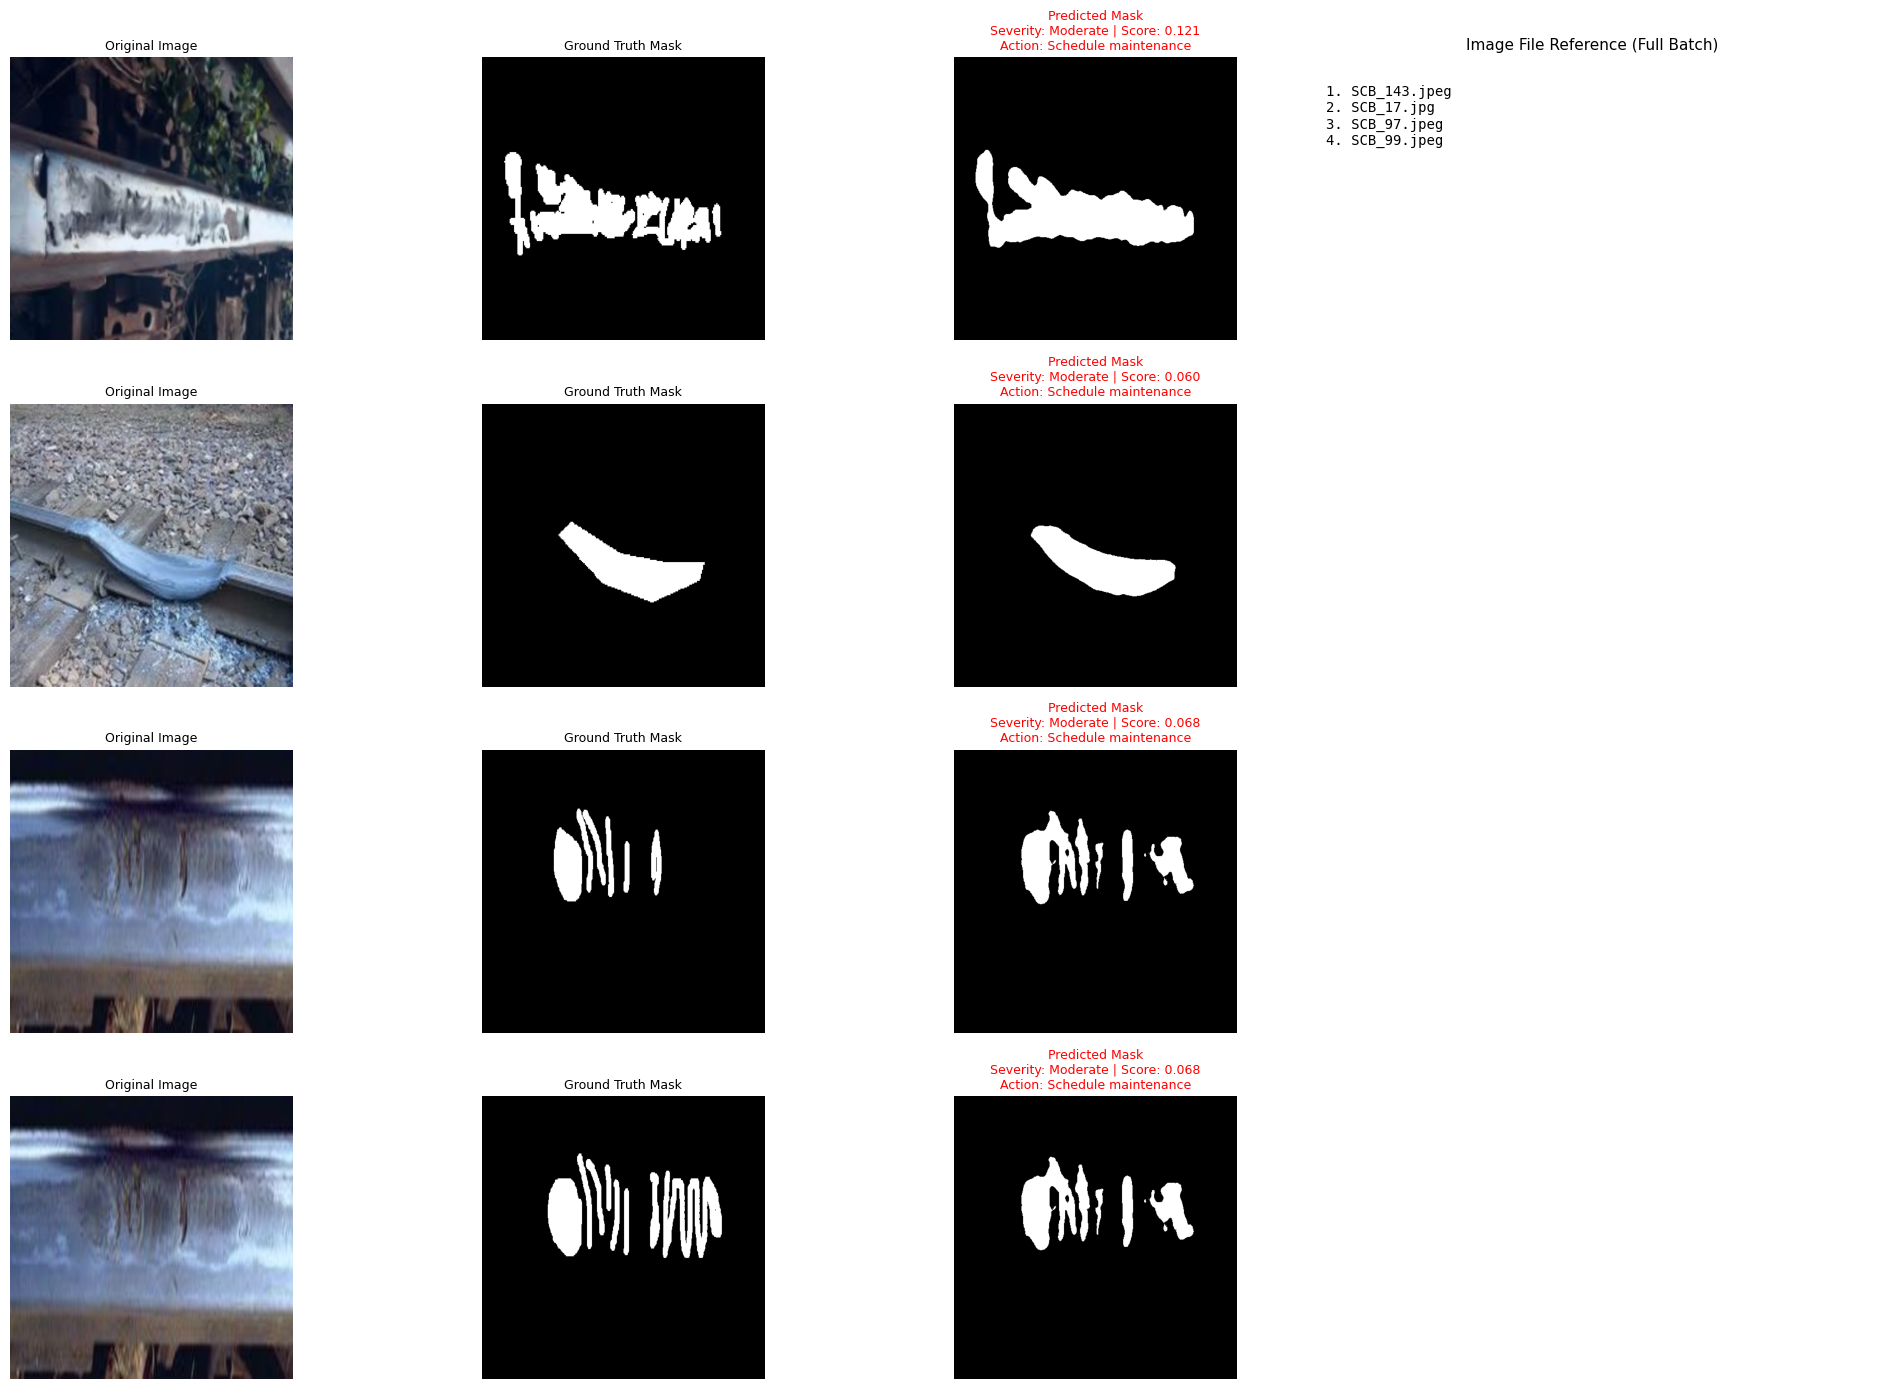

In [87]:
batch_images = []
batch_gt_masks = []
batch_pred_masks = []
batch_image_names = []

selected_files = [
    "SCB_17.jpg",
    "SCB_97.jpeg",
    "SCB_143.jpeg",
    "SCB_99.jpeg"
]

model.eval()

with torch.no_grad():

    for images, masks, image_names in test_loader:

        images = images.to(DEVICE)
        outputs = model(images)
        preds = (torch.sigmoid(outputs) > 0.5).float()

        for i, fname in enumerate(image_names):
            if fname in selected_files:

                batch_images.append(images[i].cpu())
                batch_gt_masks.append(masks[i])
                batch_pred_masks.append(preds[i].cpu())
                batch_image_names.append(fname)

        # Stop once all required images are found
        if len(batch_image_names) == len(selected_files):
            break

visualize_scabbing_batch_v3(
    images=batch_images,
    gt_masks=batch_gt_masks,
    pred_masks=batch_pred_masks,
    image_names=batch_image_names,
    max_samples=len(batch_image_names)
)

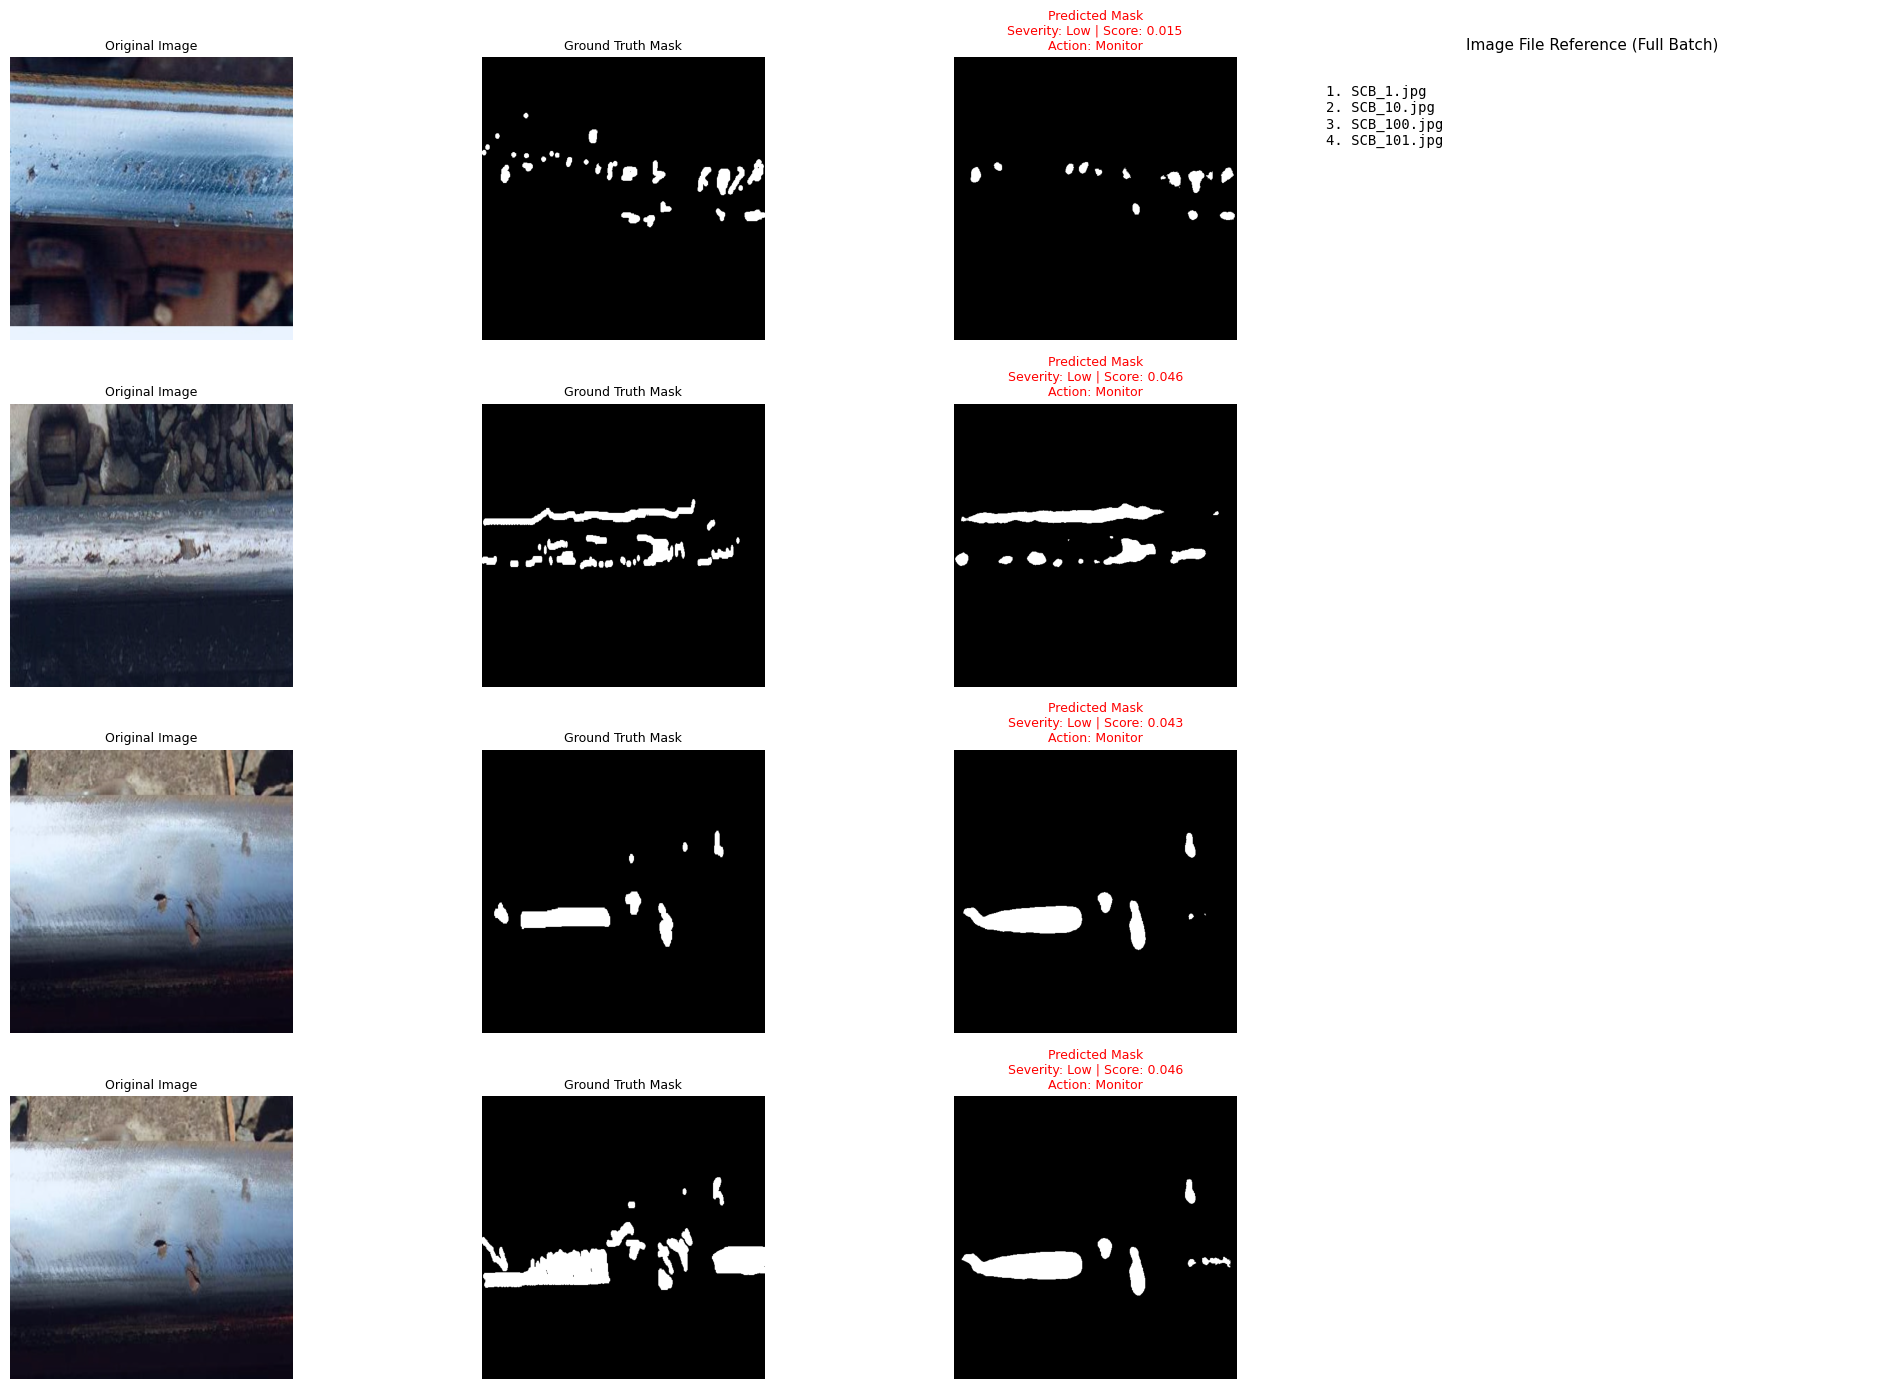

In [86]:
visualize_scabbing_batch_v3(
    images=batch_images,
    gt_masks=batch_gt_masks,
    pred_masks=batch_pred_masks,
    image_names=batch_image_names,
    max_samples=5
)


STEP 1: EXTRACT FINAL / BEST VALUES AUTOMATICALLY

In [64]:
import numpy as np

# Convert to numpy array of floats (handles tensors & NaNs)
val_dice = np.array([
    float(v) if v is not None else np.nan
    for v in history["val_dice"]
])


In [65]:
best_epoch = int(np.argmax(history["val_dice"]))

In [66]:
print("Best Epoch (1-based):", best_epoch + 1)
print("Best Val Dice:", history["val_dice"][best_epoch])


Best Epoch (1-based): 19
Best Val Dice: 0.6869531035423279


In [67]:
for k, v in history.items():
    print(k, len(v))


train_loss 20
val_loss 20
train_dice 20
val_dice 20
train_iou 20
val_iou 20
train_acc 20
val_acc 20
train_prec 20
val_prec 20
train_rec 20
val_rec 20
train_hd 20
val_hd 20


In [68]:
train_metrics = {
    "Dice": history["train_dice"][best_epoch],
    "IoU": history["train_iou"][best_epoch],
    "Accuracy": history.get("train_acc", [None])[best_epoch],
    "Precision": history.get("train_prec", [None])[best_epoch],
    "Recall": history.get("train_rec", [None])[best_epoch],
    "HD95": history["train_hd"][best_epoch]
}

val_metrics = {
    "Dice": history["val_dice"][best_epoch],
    "IoU": history["val_iou"][best_epoch],
    "Accuracy": history["val_acc"][best_epoch],
    "Precision": history["val_prec"][best_epoch],
    "Recall": history["val_rec"][best_epoch],
    "HD95": history["val_hd"][best_epoch]
}
test_metrics = {
    "Dice": test_dice,
    "IoU": test_iou,
    "Accuracy": test_acc,
    "Precision": test_prec,
    "Recall": test_rec,
    "HD95": test_hd95
}


In [69]:
best_train_epoch = int(np.nanargmax(history["train_dice"]))

train_metrics_best = {
    "Dice": history["train_dice"][best_train_epoch],
    "IoU": history["train_iou"][best_train_epoch],
    "Precision": history["train_prec"][best_train_epoch],
    "Recall": history["train_rec"][best_train_epoch],
    "HD95": history["train_hd"][best_train_epoch],
}


STEP 2: BUILD RESULTS TABLE AUTOMATICALLY (NO MANUAL VALUES)

In [70]:
import numpy as np
import pandas as pd

test_hd95_mean = float(np.mean(test_metrics["HD95"]))

results_table = pd.DataFrame({
    "Dataset Split": ["Training", "Validation", "Test"],
    "Dice Score": [
        round(train_metrics["Dice"], 4),
        round(val_metrics["Dice"], 4),
        round(test_metrics["Dice"], 4)
    ],
    "IoU": [
        round(train_metrics["IoU"], 4),
        round(val_metrics["IoU"], 4),
        round(test_metrics["IoU"], 4)
    ],
    "Accuracy": [
        round(train_metrics["Accuracy"], 4),
        round(val_metrics["Accuracy"], 4),
        round(test_metrics["Accuracy"], 4)
    ],
    "Precision": [
        round(train_metrics["Precision"], 4),
        round(val_metrics["Precision"], 4),
        round(test_metrics["Precision"], 4)
    ],
    "Recall": [
        round(train_metrics["Recall"], 4),
        round(val_metrics["Recall"], 4),
        round(test_metrics["Recall"], 4)
    ],
    "HD95 (pixels)": [
        round(train_metrics["HD95"], 2),
        round(val_metrics["HD95"], 2),
        round(test_hd95_mean, 2)
    ]
})

results_table



,Dataset Split,Dice Score,IoU,Accuracy,Precision,Recall,HD95 (pixels)
0,Training,0.6771,0.5264,0.9479,0.6690,0.7348,112.47
1,Validation,0.6870,0.5341,0.9357,0.7005,0.6955,96.63
2,Test,0.7707,0.6408,0.9669,0.7982,0.7665,72.90
